# Pobieranie prognoz z Open-Meteo S3 Bucket

Bucket: `https://openmeteo.s3.amazonaws.com`  
Struktura: `data_run/{model}/{YYYY}/{MM}/{DD}/{HHMM}Z/{variable}.om`

In [2]:
import requests
import json
import numpy as np
import shutil
import tempfile
from datetime import datetime, UTC, timedelta
from pathlib import Path

S3_BASE = "https://openmeteo.s3.amazonaws.com"

OM_MODELS = [
    "ecmwf_aifs025_single",
    "ecmwf_ifs025",
    "ecmwf_ifs",
    "ncep_gfs_graphcast025",
    "ncep_aigfs025",
    "ncep_gfs013",
    "dwd_icon",
    "meteofrance_arpege_world025",
    "ukmo_global_deterministic_10km",
    "kma_gdps",
]

## 1. Dostępne modele

Sprawdzamy metadane każdego modelu — ostatni bieg, rozdzielczość czasowa, zakres danych.

In [3]:
import pandas as pd

rows = []
for model in OM_MODELS:
    try:
        r = requests.get(f"{S3_BASE}/data/{model}/static/meta.json", timeout=15)
        r.raise_for_status()
        meta = r.json()
        last_run = datetime.fromtimestamp(meta["last_run_initialisation_time"], UTC)
        temporal_res_h = meta["temporal_resolution_seconds"] / 3600
        rows.append({
            "model": model,
            "ostatni_run": last_run.strftime("%Y-%m-%d %H:%MZ"),
            "rozdzielczosc_h": temporal_res_h,
            "aktualizacja_co_h": meta["update_interval_seconds"] / 3600,
        })
    except Exception as e:
        rows.append({"model": model, "ostatni_run": f"BŁĄD: {e}", "rozdzielczosc_h": None, "aktualizacja_co_h": None})

df_models = pd.DataFrame(rows)
df_models

,model,ostatni_run,rozdzielczosc_h,aktualizacja_co_h
0,ecmwf_aifs025_single,2026-04-11 06:00Z,6.0,6.0
1,ecmwf_ifs025,2026-04-11 06:00Z,3.0,6.0
2,ecmwf_ifs,2026-04-11 06:00Z,1.0,6.0
3,ncep_gfs_graphcast025,2026-04-11 00:00Z,6.0,6.0
4,ncep_aigfs025,2026-04-11 06:00Z,6.0,6.0
5,ncep_gfs013,2026-04-11 06:00Z,1.0,6.0
6,dwd_icon,2026-04-11 06:00Z,1.0,6.0
7,meteofrance_arpege_world025,2026-04-11 06:00Z,1.0,6.0
8,ukmo_global_deterministic_10km,2026-04-11 06:00Z,1.0,6.0
9,kma_gdps,2026-03-31 18:00Z,3.0,6.0


## 2. Wybór parametrów

Ustaw model, datę runu i ile godzin prognozy chcesz pobrać.

In [4]:
MODEL = "ecmwf_aifs025_single"          # nazwa modelu z tabeli powyżej
RUN_DATE = "2026-04-11 06:00"   # data runu (UTC), format: YYYY-MM-DD HH:MM
FORECAST_HOURS = 24             # ile godzin prognozy (np. 24, 48, 72, 120)
VARIABLE = "temperature_2m"     # zmienna do pobrania

In [5]:
run_time = datetime.strptime(RUN_DATE, "%Y-%m-%d %H:%M").replace(tzinfo=UTC)
om_url = f"{S3_BASE}/data_run/{MODEL}/{run_time:%Y/%m/%d/%H%M}Z/{VARIABLE}.om"

# Sprawdzamy czy run istnieje
r = requests.head(om_url, timeout=10)
if r.ok:
    size_mb = int(r.headers.get("Content-Length", 0)) / 1024 / 1024
    print(f"Model       : {MODEL}")
    print(f"Bieg        : {run_time:%Y-%m-%d %H:%MZ}")
    print(f"Prognoza    : {FORECAST_HOURS}h")
    print(f"Zmienna     : {VARIABLE}")
    print(f"Rozmiar     : {size_mb:.1f} MB")
    print(f"URL         : {om_url}")
else:
    print(f"Bieg niedostępny (HTTP {r.status_code}): {om_url}")
    print("Spróbuj inną datę lub sprawdź 'ostatni_bieg' w tabeli powyżej.")

Model       : ecmwf_aifs025_single
Bieg        : 2026-04-11 06:00Z
Prognoza    : 24h
Zmienna     : temperature_2m
Rozmiar     : 29.3 MB
URL         : https://openmeteo.s3.amazonaws.com/data_run/ecmwf_aifs025_single/2026/04/11/0600Z/temperature_2m.om


## 3. Pobieranie i budowa zarr

Pobieramy plik `.om` do `/tmp`, odczytujemy dane, budujemy zarr i usuwamy plik tymczasowy.

Wynik: `../predictions/<model>/<godziny>h/<data>.zarr`

In [6]:
from omfiles import OmFileReader
from scipy.interpolate import PchipInterpolator
import xarray as xr

# ── 1. Pobierz .om do /tmp ─────────────────────────────────────────

tmp_dir = Path(tempfile.mkdtemp(prefix="om_download_"))
local_om = tmp_dir / f"{VARIABLE}.om"

print(f"Pobieranie {om_url} ...")
with requests.get(om_url, stream=True, timeout=300) as resp:
    resp.raise_for_status()
    with open(local_om, "wb") as f:
        for chunk in resp.iter_content(chunk_size=4 * 1024 * 1024):
            f.write(chunk)
print(f"Pobrano: {local_om.stat().st_size / 1024 / 1024:.1f} MB → {local_om}")

# ── 2. Odczytaj dane z pliku .om ──────────────────────────────────

with OmFileReader.from_path(str(local_om)) as reader:
    raw_data = reader[:]
    time_epochs = reader.get_child_by_name("time")[:]

print(f"Kształt danych: {raw_data.shape}")
print(f"Kroków czasowych w pliku: {len(time_epochs)}")

# Filtruj do żądanego okna czasowego
run_epoch = int(run_time.timestamp())
end_epoch = int((run_time + timedelta(hours=FORECAST_HOURS)).timestamp())

# O1280 Gaussian grid (ecmwf_ifs) vs regular lat-lon
O1280_TOTAL = 6_599_680
is_gaussian = raw_data.ndim == 3 and raw_data.shape[0] == 1 and raw_data.shape[1] == O1280_TOTAL

anchors = {}
for idx, ts in enumerate(time_epochs):
    ts_int = int(ts)
    if run_epoch <= ts_int <= end_epoch:
        if is_gaussian:
            frame = np.asarray(raw_data[0, :, idx], dtype=np.float32)
        else:
            frame = np.asarray(raw_data[:, :, idx], dtype=np.float32)
            frame = np.flip(frame, axis=0)          # odwróć lat (S→N → N→S)
            frame = np.roll(frame, frame.shape[1] // 2, axis=1)  # przesunięcie lon
        anchors[ts_int] = frame

print(f"Punkty kotwiczące w oknie [{run_time:%H:%MZ} → +{FORECAST_HOURS}h]: {len(anchors)}")

# ── 3. Usuń plik tymczasowy ────────────────────────────────────────

shutil.rmtree(tmp_dir, ignore_errors=True)
print(f"Plik tymczasowy usunięty: {tmp_dir}")

Pobieranie https://openmeteo.s3.amazonaws.com/data_run/ecmwf_aifs025_single/2026/04/11/0600Z/temperature_2m.om ...
Pobrano: 29.3 MB → /tmp/om_download_xaqoh3pj/temperature_2m.om
Kształt danych: (721, 1440, 61)
Kroków czasowych w pliku: 61
Punkty kotwiczące w oknie [06:00Z → +24h]: 5
Plik tymczasowy usunięty: /tmp/om_download_xaqoh3pj


In [7]:
# ── 4. Interpolacja do godzinowej rozdzielczości (PCHIP) ───────────

target_epochs = [int((run_time + timedelta(hours=h)).timestamp()) for h in range(FORECAST_HOURS + 1)]
keys = sorted(anchors)
first, last = keys[0], keys[-1]

sample = anchors[keys[0]]
if sample.ndim == 1 and sample.shape[0] == O1280_TOTAL:
    raise NotImplementedError(
        f"Model {MODEL} używa siatki O1280 Gaussian. "
    )

lat_sz, lon_sz = sample.shape
hourly = np.full((len(target_epochs), lat_sz, lon_sz), np.nan, dtype=np.float32)

# Interpoluj chunkami
x = np.array(keys, dtype=np.float64)
inside_idx = [i for i, ts in enumerate(target_epochs) if first <= ts <= last]
x_new = np.array([target_epochs[i] for i in inside_idx], dtype=np.float64)

for lon_s in range(0, lon_sz, 48):
    lon_e = min(lon_s + 48, lon_sz)
    block = np.stack([anchors[k][:, lon_s:lon_e] for k in keys], axis=0).astype(np.float64)
    block = np.nan_to_num(block, copy=False)
    interp = PchipInterpolator(x, block, axis=0, extrapolate=False)
    hourly[inside_idx, :, lon_s:lon_e] = interp(x_new).astype(np.float32)

valid_hours = np.sum(~np.isnan(hourly[:, 0, 0]))
print(f"Interpolacja gotowa: {hourly.shape} (godzin z danymi: {valid_hours}/{len(target_epochs)})")

Interpolacja gotowa: (25, 721, 1440) (godzin z danymi: 25/25)


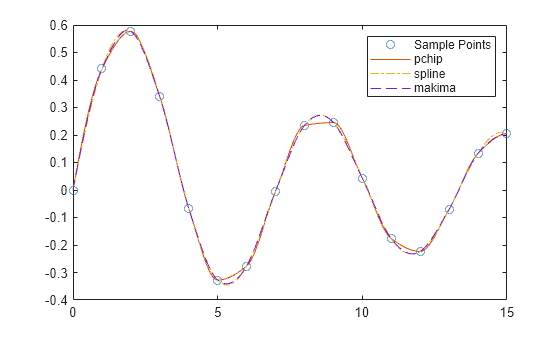

In [10]:
# ── 5. Zbuduj xarray.Dataset i zapisz jako zarr ───────────────────

# xarray/zarr nie obsługuje tz-aware datetime — używamy naive UTC
run_time_naive = run_time.replace(tzinfo=None)
valid_times = pd.date_range(run_time_naive, periods=len(target_epochs), freq="1h")
latitudes = np.linspace(90, -90, lat_sz)
longitudes = np.linspace(0, 359.75, lon_sz)

ds = xr.Dataset(
    {VARIABLE: (["valid_time", "latitude", "longitude"], hourly)},
    coords={
        "valid_time": valid_times,
        "latitude": latitudes,
        "longitude": longitudes,
    },
    attrs={
        "model": MODEL,
        "run_time": run_time.isoformat(),
        "forecast_hours": FORECAST_HOURS,
    },
)
ds

<xarray.Dataset> Size: 104MB
Dimensions:         (valid_time: 25, latitude: 721, longitude: 1440)
Coordinates:
  * valid_time      (valid_time) datetime64[us] 200B 2026-04-11T06:00:00 ... ...
  * latitude        (latitude) float64 6kB 90.0 89.75 89.5 ... -89.75 -90.0
  * longitude       (longitude) float64 12kB 0.0 0.25 0.5 ... 359.2 359.5 359.8
Data variables:
    temperature_2m  (valid_time, latitude, longitude) float32 104MB -20.2 ......
Attributes:
    model:           ecmwf_aifs025_single
    run_time:        2026-04-11T06:00:00+00:00
    forecast_hours:  24

In [11]:
# ── 6. Zapis zarr na dysk ──────────────────────────────────────────

PREDICTIONS_DIR = Path("../predictions").resolve()
zarr_dir = PREDICTIONS_DIR / MODEL / f"{FORECAST_HOURS}h"
zarr_dir.mkdir(parents=True, exist_ok=True)
zarr_path = zarr_dir / f"{run_time:%Y%m%d-%H%M}.zarr"

encoding = {VARIABLE: {"chunks": (24, 180, 360)}}
ds.to_zarr(str(zarr_path), mode="w", encoding=encoding)

print(f"Zarr zapisany: {zarr_path}")
print(f"Rozmiar: {sum(f.stat().st_size for f in zarr_path.rglob('*') if f.is_file()) / 1024 / 1024:.1f} MB")

Zarr zapisany: /home/mwasilewski/Orbitum/predictions/ecmwf_aifs025_single/24h/20260411-0600.zarr
Rozmiar: 66.8 MB


/home/mwasilewski/Orbitum/.venv/lib/python3.12/site-packages/zarr/api/asynchronous.py:247: ZarrUserWarning: Consolidated metadata is currently not part in the Zarr format 3 specification. It may not be supported by other zarr implementations and may change in the future.
  warnings.warn(


## 4. Podgląd wyniku

Szybki test — odczytujemy zarr i wyświetlamy pierwszy krok czasowy.

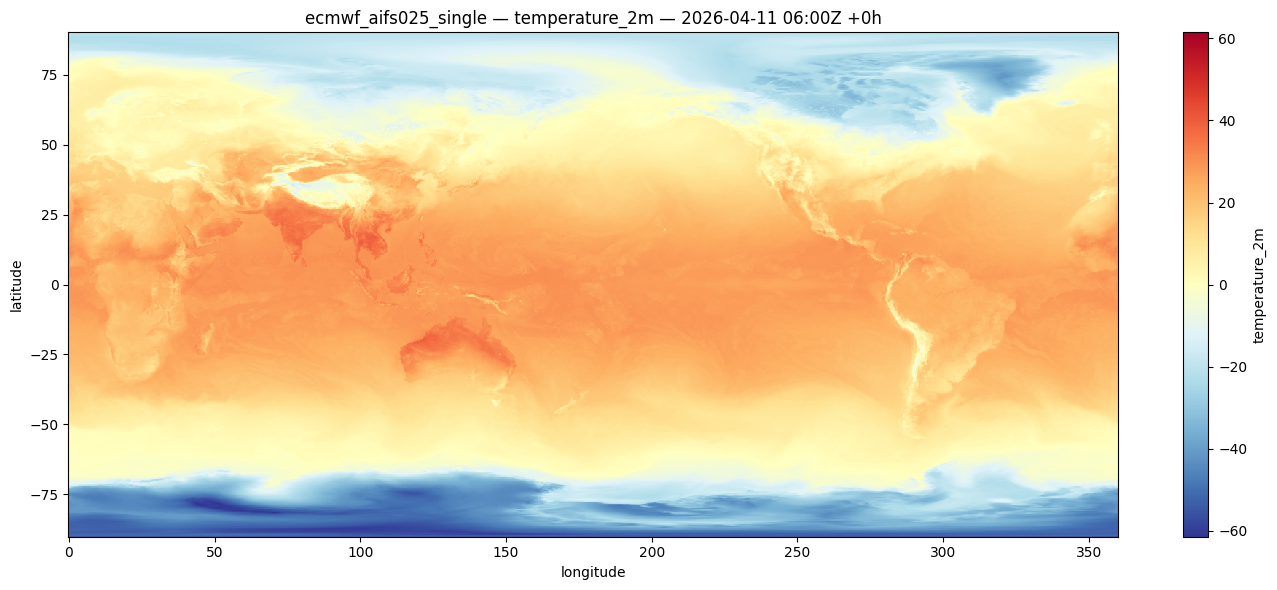


Statystyki pierwszego kroku:
  min = -61.50,  max = 41.30,  mean = 5.05


In [12]:
import matplotlib.pyplot as plt

ds_read = xr.open_zarr(str(zarr_path))
ds_read[VARIABLE].isel(valid_time=0).plot(figsize=(14, 6), cmap="RdYlBu_r")
plt.title(f"{MODEL} — {VARIABLE} — {run_time:%Y-%m-%d %H:%MZ} +0h")
plt.tight_layout()
plt.show()

print(f"\nStatystyki pierwszego kroku:")
first = ds_read[VARIABLE].isel(valid_time=0).values
print(f"  min = {np.nanmin(first):.2f},  max = {np.nanmax(first):.2f},  mean = {np.nanmean(first):.2f}")